# Laboratorio de clasificación 3

|                |   |
:----------------|---|
| **Nombre**     | Carlos Enrique Nieves Ochoa |
| **Fecha**      | 19 de octubre de 2026 |
| **Expediente** | 758210 |

Una regresión logística simple toma **P** predictores y usa una función no lineal para convertir la respuesta binaria **Y** en probabilidades entre $0$ y $1$.

La visualización de este escenario es puntos separados por una línea recta.

<center><img src="https://wirelesspi.com/wp-content/uploads/2022/08/figure-logistic-regression-decision-boundary-2-570x550.png"></center>

Para casos donde los datos no son linealmente separables usamos el truco del kernel para mapear los datos a un espacio de Hilbert.

Imagina un escenario donde tienes dos predictores $x_1, x_2$ y la salida de estos predictores se comporta de esta manera:

| **$x_1$** | **$x_2$** | Salida |
:-----------|-----------|--------|
| 0         | 0         | 0      |
| 0         | 1         | 1      |
| 1         | 0         | 1      |
| 1         | 1         | 0      |


Imagínalo como el interruptos de luz de un foco en una escalera. Se puede prender y apagar desde arriba y desde abajo.

<center><img src="https://www.researchgate.net/profile/Brian-Spears/publication/322048911/figure/fig4/AS:667820685807618@1536232267250/The-exclusive-or-XOR-function-is-a-nonlinear-function-that-returns-0-when-its-two.png"></center>

**¿Cómo podemos separar estos datos usando sólo regresión logística?** Sin importar cómo usemos una sola línea, nunca se van a poder separar todos los casos, por lo que tendríamos situaciones donde siempre habría error. 

Solución: **¿Por qué nos estamos limitando a una sola línea?**

<center><img src="https://pabloinsente.github.io/assets/post-5/XOR-linear.png"></center>

La regresión logística sola es un método de aprendizaje estadístico convexo. Combinar dos regresiones logísticas para clasificar datos no linealmente separables convierte el problema a uno no convexo. **¿Por qué?**

- **Respuesta:** una regresión logística sola es básicamente una sigmoide encima de una combinación lineal, y su log-loss tiene forma de "taza": hay un solo fondo y, empieces donde empieces, llegas ahí. El problema es que al juntar dos regresiones logísticas metemos una sigmoide dentro de otra, y esa composición de funciones no lineales rompe la forma de taza. La pérdida se llena de valles y mesetas. Además pasa algo curioso: si intercambias las dos neuronas ocultas, el modelo es exactamente el mismo pero con los pesos en otro orden, así que ya hay por lo menos dos mínimos igual de buenos. Con más de un mínimo, la función ya no puede ser convexa.

**¿Qué significa que una función sea convexa?**

- **Respuesta:** que tiene forma de taza: si unes dos puntos de la curva con una recta, la recta nunca queda por debajo. Lo bueno es que solo tiene un fondo, así que el mínimo que encuentres es el mínimo de toda la función.

**¿Por qué nos importa que una función sea convexa o no? ¿Qué impacto tiene para los resultados?**

- **Respuesta:** porque de eso depende qué tanto puedo confiar en lo que me da el optimizador. Con una función convexa da igual desde dónde arranque: siempre llego al mismo mínimo y, si corro el modelo dos veces, obtengo lo mismo. Con una red neuronal no pasa eso. El optimizador puede atorarse en un mínimo local o en una zona plana, y el resultado cambia según cómo se inicialicen los pesos (`random_state`), la tasa de aprendizaje o cuántas iteraciones le dé. En la práctica eso significa que hay que probar varias combinaciones de hiperparámetros y aceptar que nunca tengo garantía de haber encontrado la mejor solución.

## **Ejercicio 1**

Utilizaremos el clasificador `MLPClassifier` de la librería `sklearn`.

Entra a la documentación y describe cómo funciona este objeto (qué entradas necesita, qué salidas da, descripción de sus hiperparámetros).

- **Respuesta:** `MLPClassifier` (está en `sklearn.neural_network`) es un perceptrón multicapa, o sea, una red neuronal con una o más capas ocultas en medio. Cada neurona hace lo mismo que una regresión logística chiquita: combina linealmente lo que le llega y le aplica una función de activación. Al final, la capa de salida da la probabilidad con una logística (si son dos clases) o una softmax (si son más). Para aprender, la red ajusta sus pesos minimizando la log-loss con retropropagación y un optimizador (`adam`, `sgd` o `lbfgs`).

**¿Qué necesita?** Igual que los otros modelos de sklearn, `fit(X, y)`: una matriz `X` de $n \times p$ solo con números y un vector `y` con las etiquetas. Conviene escalar `X` antes, porque la red es muy sensible a la escala de las variables.

**¿Qué regresa?**
- `predict(X)`: la clase que predice para cada observación.
- `predict_proba(X)`: la probabilidad de cada clase; con `[:, 1]` me quedo con la de la clase positiva.
- `score(X, y)`: el accuracy.
- Y ya entrenado guarda cosas útiles: `classes_` (las clases), `coefs_` e `intercepts_` (pesos y sesgos de cada capa), `loss_` (la pérdida final), `loss_curve_` (cómo bajó la pérdida en cada iteración) y `n_iter_` (cuántas iteraciones hizo).

**Hiperparámetros que más se mueven:**

| Hiperparámetro | Por defecto | Para qué sirve |
| :- | :- | :- |
| `hidden_layer_sizes` | `(100,)` | Cuántas neuronas tiene cada capa oculta; `(50, 25)` son dos capas, una de 50 y otra de 25. |
| `activation` | `"relu"` | La función de activación de las capas ocultas: `"identity"`, `"logistic"`, `"tanh"` o `"relu"`. |
| `solver` | `"adam"` | El optimizador: `"lbfgs"` va bien con pocos datos, `"sgd"` es descenso de gradiente estocástico y `"adam"` es el más usado. |
| `alpha` | `0.0001` | Qué tanto se penalizan los pesos grandes (L2); si lo subo, el modelo se sobreajusta menos. |
| `batch_size` | `"auto"` | Cuántas observaciones usa en cada paso con `sgd` o `adam` (por defecto `min(200, n)`). |
| `learning_rate` | `"constant"` | Si la tasa de aprendizaje de `sgd` se queda fija, baja poco a poco (`"invscaling"`) o se ajusta sola (`"adaptive"`). |
| `learning_rate_init` | `0.001` | Qué tan grandes son los pasos al inicio con `sgd` y `adam`. |
| `max_iter` | `200` | El máximo de épocas (o de iteraciones con `lbfgs`). |
| `tol` | `1e-4` | Si la pérdida mejora menos que esto, deja de entrenar. |
| `early_stopping` | `False` | Si lo pongo en `True`, aparta un pedazo del entrenamiento para validar y se para cuando ya no mejora. |
| `validation_fraction` | `0.1` | Qué parte se aparta para validar cuando `early_stopping=True`. |
| `shuffle` | `True` | Revuelve los datos en cada época (con `sgd` y `adam`). |
| `momentum` | `0.9` | El "impulso" del descenso de gradiente con `sgd`. |
| `random_state` | `None` | La semilla de los pesos iniciales y de la mezcla; con ella los resultados salen iguales cada vez. |

## **Ejercicio 2**

Utiliza el objeto de perceptrón multicapa para clasificar si un tumor es maligno o benigno con el dataset `Brain Tumor Dataset`. Utiliza un cross-validation de train-test de 70/30. Sigue todos los pasos de EDA y limpieza vistos.

In [1]:
# Librerías
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.neural_network import MLPClassifier
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import roc_auc_score, classification_report, confusion_matrix

### EDA

In [2]:
df = pd.read_csv("brain_tumor_dataset.csv")
df.head()

,Patient_ID,Age,Gender,Tumor_Type,Tumor_Size,Location,Histology,Stage,Symptom_1,Symptom_2,Symptom_3,Radiation_Treatment,Surgery_Performed,Chemotherapy,Survival_Rate,Tumor_Growth_Rate,Family_History,MRI_Result,Follow_Up_Required
0,1,73,Male,Malignant,5.375612,Temporal,Astrocytoma,III,Vision Issues,Seizures,Seizures,No,No,No,51.312579,0.111876,No,Positive,Yes
1,2,26,Male,Benign,4.847098,Parietal,Glioblastoma,II,Headache,Headache,Nausea,Yes,Yes,Yes,46.373273,2.165736,Yes,Positive,Yes
2,3,31,Male,Benign,5.588391,Parietal,Meningioma,I,Vision Issues,Headache,Seizures,No,No,No,47.072221,1.884228,No,Negative,No
3,4,29,Male,Malignant,1.436600,Temporal,Medulloblastoma,IV,Vision Issues,Seizures,Headache,Yes,No,Yes,51.853634,1.283342,Yes,Negative,No
4,5,54,Female,Benign,2.417506,Parietal,Glioblastoma,I,Headache,Headache,Seizures,No,No,Yes,54.708987,2.069477,No,Positive,Yes


In [3]:
print(df.shape)
df.info()

(20000, 19)
<class 'pandas.DataFrame'>
RangeIndex: 20000 entries, 0 to 19999
Data columns (total 19 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Patient_ID           20000 non-null  int64  
 1   Age                  20000 non-null  int64  
 2   Gender               20000 non-null  str    
 3   Tumor_Type           20000 non-null  str    
 4   Tumor_Size           20000 non-null  float64
 5   Location             20000 non-null  str    
 6   Histology            20000 non-null  str    
 7   Stage                20000 non-null  str    
 8   Symptom_1            20000 non-null  str    
 9   Symptom_2            20000 non-null  str    
 10  Symptom_3            20000 non-null  str    
 11  Radiation_Treatment  20000 non-null  str    
 12  Surgery_Performed    20000 non-null  str    
 13  Chemotherapy         20000 non-null  str    
 14  Survival_Rate        20000 non-null  float64
 15  Tumor_Growth_Rate    20000 non-null

In [4]:
df.describe()

,Patient_ID,Age,Tumor_Size,Survival_Rate,Tumor_Growth_Rate
count,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000
mean,10000.500000,49.433700,5.236552,70.131699,1.547701
std,5773.647028,17.389296,2.754359,17.270834,0.835995
min,1.000000,20.000000,0.500410,40.002386,0.100017
25%,5000.750000,34.000000,2.836686,55.224439,0.830433
50%,10000.500000,49.000000,5.200675,70.305066,1.541821
75%,15000.250000,65.000000,7.624299,85.043395,2.262484
max,20000.000000,79.000000,9.999420,99.998125,2.999835


In [5]:
# Valores faltantes y duplicados
print(df.isna().sum())
print("Duplicados:", df.duplicated().sum())

Patient_ID             0
Age                    0
Gender                 0
Tumor_Type             0
Tumor_Size             0
Location               0
Histology              0
Stage                  0
Symptom_1              0
Symptom_2              0
Symptom_3              0
Radiation_Treatment    0
Surgery_Performed      0
Chemotherapy           0
Survival_Rate          0
Tumor_Growth_Rate      0
Family_History         0
MRI_Result             0
Follow_Up_Required     0
dtype: int64
Duplicados: 0


In [6]:
# Balance de la variable respuesta
df["Tumor_Type"].value_counts()

Tumor_Type
Malignant    10030
Benign        9970
Name: count, dtype: int64

In [7]:
# Frecuencias de las variables categóricas
for col in ["Gender", "Location", "Histology", "Stage", "Symptom_1", "Symptom_2", "Symptom_3",
            "Radiation_Treatment", "Surgery_Performed", "Chemotherapy", "Family_History",
            "MRI_Result", "Follow_Up_Required"]:
    print(df[col].value_counts(), "\n")

Gender
Female    10016
Male       9984
Name: count, dtype: int64 

Location
Temporal     5118
Parietal     4990
Occipital    4967
Frontal      4925
Name: count, dtype: int64 

Histology
Glioblastoma       5068
Meningioma         5016
Medulloblastoma    4979
Astrocytoma        4937
Name: count, dtype: int64 

Stage
II     5093
I      4986
IV     4968
III    4953
Name: count, dtype: int64 

Symptom_1
Headache         5045
Seizures         5028
Nausea           4969
Vision Issues    4958
Name: count, dtype: int64 

Symptom_2
Seizures         5054
Vision Issues    5019
Headache         4996
Nausea           4931
Name: count, dtype: int64 

Symptom_3
Seizures         5027
Nausea           5012
Vision Issues    5007
Headache         4954
Name: count, dtype: int64 

Radiation_Treatment
Yes    10021
No      9979
Name: count, dtype: int64 

Surgery_Performed
Yes    10060
No      9940
Name: count, dtype: int64 

Chemotherapy
Yes    10097
No      9903
Name: count, dtype: int64 

Family_History
No

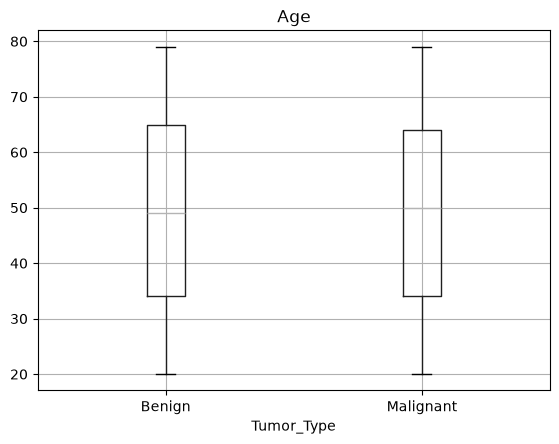

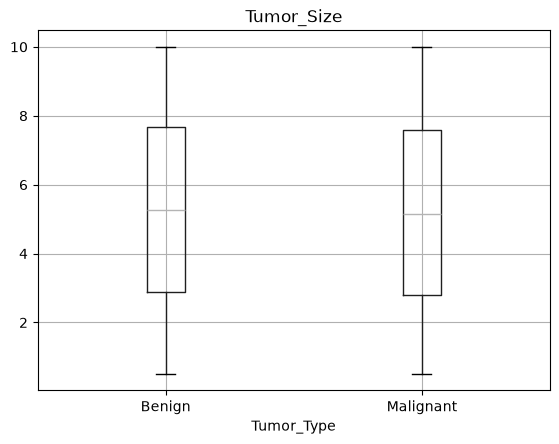

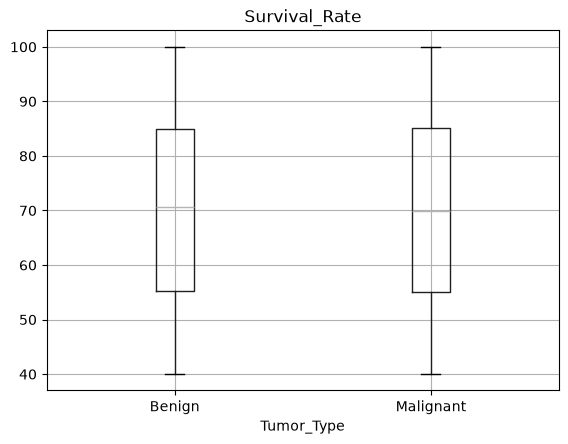

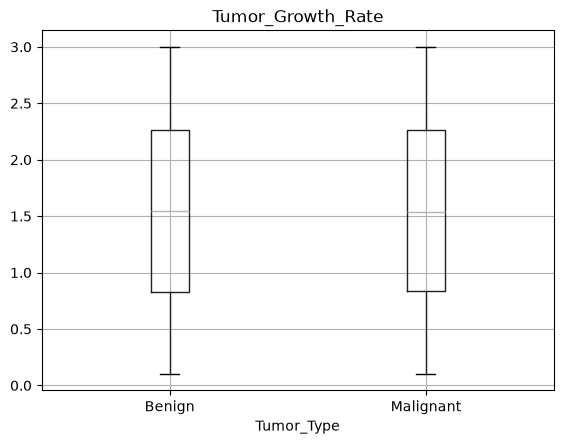

In [8]:
# Variables numéricas según el tipo de tumor
for col in ["Age", "Tumor_Size", "Survival_Rate", "Tumor_Growth_Rate"]:
    df.boxplot(column=col, by="Tumor_Type")
    plt.suptitle("")
    plt.title(col)
    plt.show()

Tenemos 20,000 pacientes y 19 columnas, sin datos faltantes ni filas repetidas, así que no hay que quitar nada. Las clases vienen balanceadísimas (10,030 malignos contra 9,970 benignos) y, la verdad, todo está sospechosamente parejo: cada variable categórica se reparte casi exacto entre sus categorías (como 50 % o 25 % cada una). Las numéricas viven en rangos fijos (edades de 20 a 79, tamaños de 0.5 a 10 cm) y en los diagramas de caja malignos y benignos se ven prácticamente iguales; por ejemplo, la mediana del tamaño es 5.27 en benignos y 5.14 en malignos. Todo apunta a que el dataset es sintético, generado al azar, y desde aquí ya se ve que las variables no van a ayudar mucho a distinguir un tumor del otro.

### Limpieza

In [9]:
# Patient_ID solo identifica al paciente, no aporta información
df = df.drop(columns=["Patient_ID"])

# Variable respuesta: 1 = maligno, 0 = benigno
y = (df["Tumor_Type"] == "Malignant").astype(int)
X = df.drop(columns=["Tumor_Type"])

# Stage es ordinal
X["Stage"] = X["Stage"].map({"I": 1, "II": 2, "III": 3, "IV": 4})

# Variables Yes/No y Positive/Negative a 0 y 1
for col in ["Radiation_Treatment", "Surgery_Performed", "Chemotherapy", "Family_History", "Follow_Up_Required"]:
    X[col] = (X[col] == "Yes").astype(int)
X["MRI_Result"] = (X["MRI_Result"] == "Positive").astype(int)

X.head()

,Age,Gender,Tumor_Size,Location,Histology,Stage,Symptom_1,Symptom_2,Symptom_3,Radiation_Treatment,Surgery_Performed,Chemotherapy,Survival_Rate,Tumor_Growth_Rate,Family_History,MRI_Result,Follow_Up_Required
0,73,Male,5.375612,Temporal,Astrocytoma,3,Vision Issues,Seizures,Seizures,0,0,0,51.312579,0.111876,0,1,1
1,26,Male,4.847098,Parietal,Glioblastoma,2,Headache,Headache,Nausea,1,1,1,46.373273,2.165736,1,1,1
2,31,Male,5.588391,Parietal,Meningioma,1,Vision Issues,Headache,Seizures,0,0,0,47.072221,1.884228,0,0,0
3,29,Male,1.436600,Temporal,Medulloblastoma,4,Vision Issues,Seizures,Headache,1,0,1,51.853634,1.283342,1,0,0
4,54,Female,2.417506,Parietal,Glioblastoma,1,Headache,Headache,Seizures,0,0,1,54.708987,2.069477,0,1,1


In [10]:
numerical_cols = ["Age", "Tumor_Size", "Survival_Rate", "Tumor_Growth_Rate", "Stage"]
categorical_cols = ["Gender", "Location", "Histology", "Symptom_1", "Symptom_2", "Symptom_3"]
boolean_cols = ["Radiation_Treatment", "Surgery_Performed", "Chemotherapy", "Family_History",
                "MRI_Result", "Follow_Up_Required"]

preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numerical_cols),
        ("cat", OneHotEncoder(), categorical_cols),
        ("bool", "passthrough", boolean_cols)
    ],
    remainder="drop"
)

### Modelo

In [11]:
# Separación 70/30
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", MLPClassifier(random_state=42))
    ]
)

pipeline.fit(X_train, y_train)

prob = pipeline.predict_proba(X_test)[:, 1]
y_pred = (prob >= 0.5).astype(int)

c:\Users\carlo\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(


In [12]:
# Métricas con el conjunto de prueba
tp = ((y_pred == 1) & (y_test == 1)).sum()
tn = ((y_pred == 0) & (y_test == 0)).sum()
fp = ((y_pred == 1) & (y_test == 0)).sum()
fn = ((y_pred == 0) & (y_test == 1)).sum()

acc = (tp + tn) / (tp + tn + fp + fn)
rec = tp / (tp + fn)
pre = tp / (tp + fp)
esp = tn / (tn + fp)
auc = roc_auc_score(y_test, prob)

pd.DataFrame({"Métrica": ["Accuracy", "Recall", "Precisión", "Especificidad", "AUC"],
              "Valor": [acc, rec, pre, esp, auc]})

,Métrica,Valor
0,Accuracy,0.496167
1,Recall,0.566491
2,Precisión,0.502189
3,Especificidad,0.424038
4,AUC,0.495765


In [13]:
print(classification_report(y_test, y_pred, target_names=["Benigno", "Maligno"]))

              precision    recall  f1-score   support

     Benigno       0.49      0.42      0.45      2962
     Maligno       0.50      0.57      0.53      3038

    accuracy                           0.50      6000
   macro avg       0.50      0.50      0.49      6000
weighted avg       0.50      0.50      0.49      6000



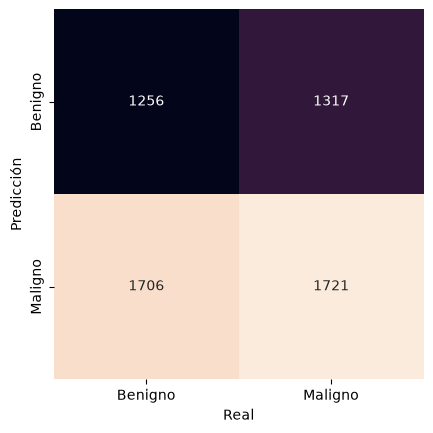

In [14]:
mat = confusion_matrix(y_test, y_pred)
sns.heatmap(mat.T, square=True, annot=True, fmt="d", cbar=False,
            xticklabels=["Benigno", "Maligno"], yticklabels=["Benigno", "Maligno"])
plt.xlabel("Real")
plt.ylabel("Predicción")
plt.show()

Con los hiperparámetros por defecto, el perceptrón saca en prueba un accuracy de 0.496, un recall de 0.566, una precisión de 0.502, una especificidad de 0.424 y un AUC de 0.496. Dicho de otra forma: un AUC de 0.5 es lo mismo que echar un volado, así que el modelo no está distinguiendo malignos de benignos. Si atrapa el 57 % de los malignos es solo porque tiende a decir "maligno" más seguido, y lo paga equivocándose con el 58 % de los benignos. También sale un aviso de que el optimizador no convergió en 200 iteraciones, que tiene sentido: la red está intentando aprenderse ruido.

Aquí el problema no es el MLP, son los datos. Como vimos en el EDA, las variables se distribuyen igual en los dos tipos de tumor, entonces no hay ningún patrón que aprender, y con este dataset ningún clasificador serviría para un diagnóstico real.

**¿Qué métrico crees que sea mejor para este ejercicio?** Escoge los 3 métricos que crees más apropiados para esta predicción, argumenta en pro y en contra del top 3. Elige uno para optimizar (justifica tu respuesta).

- **Respuesta:** mi top 3 sería este:

1. **Recall (sensibilidad):** de todos los tumores malignos, cuántos detecta el modelo.
   - *A favor:* va directo al error que más duele aquí, el falso negativo. Decirle a alguien que su tumor es benigno cuando no lo es retrasa su tratamiento.
   - *En contra:* es fácil hacerle trampa. Si el modelo dice "maligno" para todos, el recall sale 1 y el modelo no sirve para nada, porque no le importan los falsos positivos.
2. **AUC:** qué tan seguido el modelo le da más probabilidad a un tumor maligno que a uno benigno.
   - *A favor:* no depende del umbral y me dice de un vistazo si el modelo separa las clases o no (0.5 = no separa nada).
   - *En contra:* no me dice qué pasa con el umbral que de verdad voy a usar, ni distingue entre un tipo de error y otro.
3. **Precisión:** de los que el modelo marca como malignos, cuántos sí lo son.
   - *A favor:* cuida los falsos positivos, que se traducen en estudios, cirugías o tratamientos que no hacían falta.
   - *En contra:* puede verse muy bien aunque al modelo se le escapen muchos malignos, porque no toma en cuenta los falsos negativos.

El accuracy lo dejé fuera. Como las clases están balanceadas sí tiene sentido, pero cuenta igual un falso negativo que un falso positivo, y aquí no pesan lo mismo.

**La que voy a optimizar es el recall.** En un diagnóstico de tumores, que se te pase uno maligno es mucho peor que una falsa alarma, que luego se puede descartar con más estudios. Eso sí, para que no se infle nada más prediciendo todo como maligno, lo voy a ver siempre junto con la precisión y el AUC.

## **Ejercicio 3**

Modifica los hiperparámetros para elevar el métrico elegido. Intenta con 10 sets de hiperparámetros distintos. Crea una tabla que muestre los resultados.

In [15]:
# 10 sets de hiperparámetros
modelos = [
    ("(100,) relu adam", MLPClassifier(random_state=42)),
    ("(50,) relu adam", MLPClassifier(hidden_layer_sizes=(50,), random_state=42)),
    ("(10,) relu adam", MLPClassifier(hidden_layer_sizes=(10,), random_state=42)),
    ("(100, 50) relu adam", MLPClassifier(hidden_layer_sizes=(100, 50), random_state=42)),
    ("(50,) tanh adam", MLPClassifier(hidden_layer_sizes=(50,), activation="tanh", random_state=42)),
    ("(50,) logistic adam", MLPClassifier(hidden_layer_sizes=(50,), activation="logistic", random_state=42)),
    ("(50,) relu adam alpha=1", MLPClassifier(hidden_layer_sizes=(50,), alpha=1, random_state=42)),
    ("(50,) relu adam lr=0.01", MLPClassifier(hidden_layer_sizes=(50,), learning_rate_init=0.01, random_state=42)),
    ("(50,) relu sgd lr=0.01", MLPClassifier(hidden_layer_sizes=(50,), solver="sgd", learning_rate_init=0.01, random_state=42)),
    ("(20,) tanh lbfgs", MLPClassifier(hidden_layer_sizes=(20,), activation="tanh", solver="lbfgs", max_iter=500, random_state=42)),
]

In [16]:
resultados = []

for nombre, modelo in modelos:
    pipeline = Pipeline(
        steps=[
            ("preprocessor", preprocessor),
            ("model", modelo)
        ]
    )

    pipeline.fit(X_train, y_train)
    prob = pipeline.predict_proba(X_test)[:, 1]
    y_pred = (prob >= 0.5).astype(int)

    tp = ((y_pred == 1) & (y_test == 1)).sum()
    tn = ((y_pred == 0) & (y_test == 0)).sum()
    fp = ((y_pred == 1) & (y_test == 0)).sum()
    fn = ((y_pred == 0) & (y_test == 1)).sum()

    rec = tp / (tp + fn)
    pre = tp / (tp + fp)
    acc = (tp + tn) / (tp + tn + fp + fn)
    auc = roc_auc_score(y_test, prob)

    resultados.append([nombre, rec, pre, acc, auc])

pd.DataFrame(resultados, columns=["Modelo", "Recall", "Precisión", "Accuracy", "AUC"])

c:\Users\carlo\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(
c:\Users\carlo\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(
c:\Users\carlo\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(
c:\Users\carlo\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the opti

,Modelo,Recall,Precisión,Accuracy,AUC
0,"(100,) relu adam",0.566491,0.502189,0.496167,0.495765
1,"(50,) relu adam",0.474984,0.494178,0.488000,0.488059
2,"(10,) relu adam",0.470704,0.502460,0.496000,0.491707
3,"(100, 50) relu adam",0.497696,0.505517,0.499167,0.498311
4,"(50,) tanh adam",0.518433,0.504323,0.498167,0.491286
5,"(50,) logistic adam",0.762014,0.509800,0.508500,0.506550
6,"(50,) relu adam alpha=1",0.444371,0.506377,0.499333,0.503258
7,"(50,) relu adam lr=0.01",0.515471,0.504185,0.498000,0.499918
8,"(50,) relu sgd lr=0.01",0.491113,0.504224,0.497833,0.491253
9,"(20,) tanh lbfgs",0.491771,0.510072,0.503500,0.504173


El recall más alto lo dio la red con una capa de 50 neuronas y activación `logistic`: 0.762, contra 0.566 del modelo base. Suena a gran mejora, pero no lo es tanto: su precisión y su AUC siguen en 0.51, igual que en los demás. Lo único que cambió es que esa red dice "maligno" para muchos más pacientes, así que atrapa más malignos pero también suelta muchos más falsos positivos. Si vemos los diez sets juntos, el AUC va de 0.488 a 0.507 y el accuracy de 0.488 a 0.509, o sea, todo en nivel de azar.

Las diferencias de recall entre configuraciones (de 0.444 a 0.762) no son que un modelo sea mejor que otro; son cada red inclinándose hacia una clase o hacia la otra según cómo arrancó y qué optimizador usó, justo lo que pasa cuando el problema no es convexo. Varias ni siquiera convergieron. La conclusión es que, con estas variables, por más que le mueva a los hiperparámetros no voy a subir el recall de verdad sin perder precisión, porque los datos simplemente no traen información sobre el tipo de tumor.